In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel/Cyclone_Wildfire_Flood_Earthquake_Dataset/readme.txt
/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel/Cyclone_Wildfire_Flood_Earthquake_Dataset/Flood/623.jpg
/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel/Cyclone_Wildfire_Flood_Earthquake_Dataset/Flood/764.jpg
/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel/Cyclone_Wildfire_Flood_Earthquake_Dataset/Flood/771.jpg
/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel/Cyclone_Wildfire_Flood_Earthquake_Dataset/Flood/208.jpg
/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel/Cyclone_Wildfire_Flood_Earthquake_Dataset/Flood/820.jpg
/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel/Cyclone_Wildfire_Flood_Earthquake_Dataset/Flood/473.jpg
/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel/Cyclone_Wildfire_Flood_Earthquake_Dataset/Flood/1031.jpg
/kaggle/input/zero-shot-di

In [2]:
# Cell 1: Install required packages and import libraries
!pip install git+https://github.com/openai/CLIP.git

import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.models as models
import clip
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import os
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# Set device
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-84kuiorz
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-84kuiorz
  Resolved https://github.com/openai/CLIP.git to commit dcba3cb2e2827b402d2701e7e1c7d9fed8a20ef1
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 5.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 104.4 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 75.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 8.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 

In [3]:
# Cell 2: Data exploration and visualization
def explore_dataset(base_path):
    """Explore the dataset structure and show sample images"""
    print("Dataset Structure:")
    print("=" * 50)
    
    for split in ['train', 'validation', 'test']:
        split_path = os.path.join(base_path, split)
        if os.path.exists(split_path):
            print(f"\n{split.upper()} SET:")
            for class_name in os.listdir(split_path):
                class_path = os.path.join(split_path, class_name)
                if os.path.isdir(class_path):
                    num_images = len([f for f in os.listdir(class_path) if f.endswith(('.jpg', '.png', '.jpeg'))])
                    print(f"  {class_name}: {num_images} images")

# You'll need to update this path to match your actual dataset path
# Let's first check what paths are available
print("Available directories in /kaggle/input:")
for dirname, _, filenames in os.walk('/kaggle/input'):
    if dirname == '/kaggle/input':
        for filename in filenames[:10]:  # Show first 10 files
            print(os.path.join(dirname, filename))
        break

# Update this path based on what you see above
dataset_path = "/kaggle/input/disaster-management-zero-shot-recognition/DisasterModel"  # You might need to change this

# Explore dataset if the path exists
if os.path.exists(dataset_path):
    explore_dataset(dataset_path)
else:
    print(f"Dataset path {dataset_path} not found. Please update the dataset_path variable.")

Available directories in /kaggle/input:
Dataset path /kaggle/input/disaster-management-zero-shot-recognition/DisasterModel not found. Please update the dataset_path variable.


In [4]:
# Cell 3: Let's find the correct dataset path
print("Searching for dataset directories...")
possible_paths = []
for dirname, _, filenames in os.walk('/kaggle/input'):
    # Look for directories that might contain our dataset
    if 'train' in dirname or 'test' in dirname or 'validation' in dirname:
        possible_paths.append(dirname)
    # Also check if this directory contains image files or disaster-related folders
    if any(disaster in dirname.lower() for disaster in ['cyclone', 'wildfire', 'flood', 'earthquake', 'disaster']):
        possible_paths.append(dirname)

print("Possible dataset paths:")
for path in set(possible_paths[:20]):  # Show first 20 unique paths
    print(path)

# Let's try to find a path that has train, validation, test subdirectories
print("\n" + "="*50)
print("Looking for paths with train/validation/test structure...")
for dirname, subdirs, _ in os.walk('/kaggle/input'):
    if 'train' in subdirs and 'test' in subdirs:
        print(f"Found structured dataset at: {dirname}")
        dataset_path = dirname
        break
else:
    # If we didn't find a structured dataset, use the first input directory
    dataset_path = '/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel'
    print(f"Using base input directory: {dataset_path}")

print(f"Final dataset path: {dataset_path}")

Searching for dataset directories...
Possible dataset paths:
/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel/Cyclone_Wildfire_Flood_Earthquake_Dataset/Flood
/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel/Cyclone_Wildfire_Flood_Earthquake_Dataset/Earthquake
/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel/Cyclone_Wildfire_Flood_Earthquake_Dataset/Wildfire
/kaggle/input/zero-shot-disaster-management-dataset
/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel/Cyclone_Wildfire_Flood_Earthquake_Dataset
/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel
/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel/validation/cyclone
/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel/test/thunderstorm
/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel/validation/wildfire
/kaggle/input/zero-shot-disaster-management-dataset/DisasterModel/test
/kaggle/input/zero-shot-disaster-mana

Found classes: ['flood', 'cyclone', 'wildfire', 'earthquake', 'thunderstorm', 'sandstorm', 'drought']


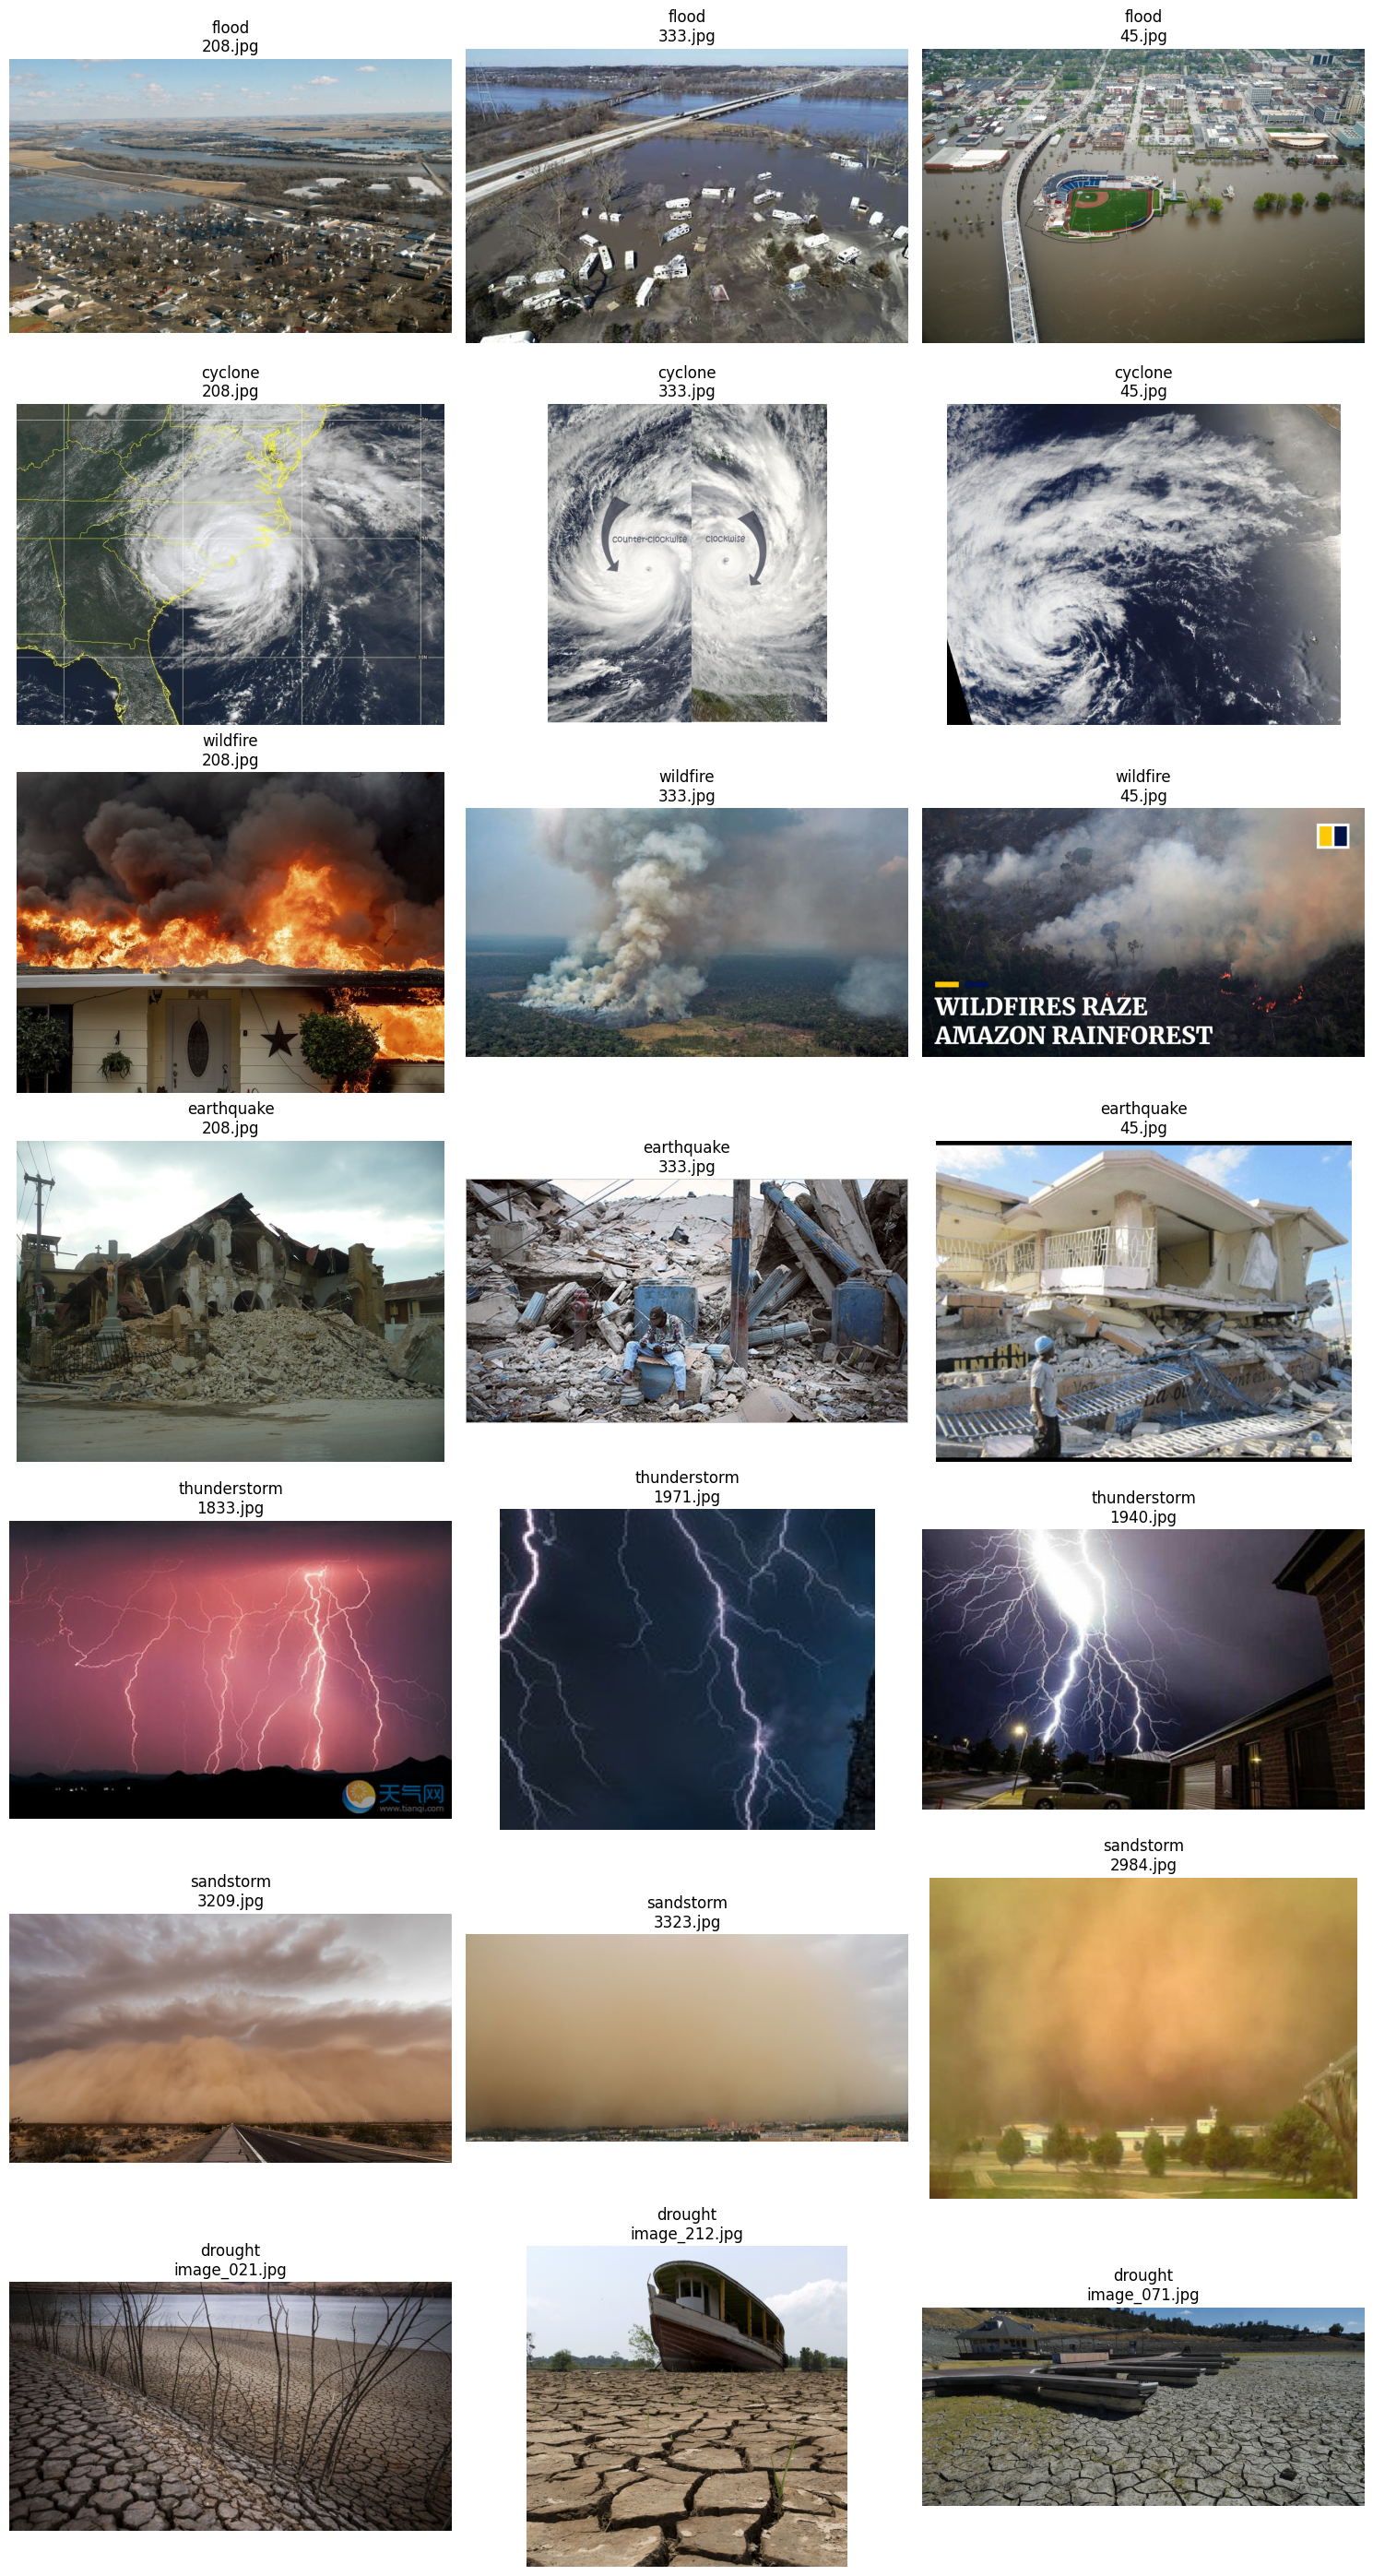

In [5]:
# Cell 4: Display sample images from each class
def display_sample_images(base_path, num_samples=3):
    """Display sample images from each class"""
    # First, let's find what classes we have
    classes_found = []
    for split in ['train', 'validation', 'test']:
        split_path = os.path.join(base_path, split)
        if os.path.exists(split_path):
            for class_name in os.listdir(split_path):
                class_path = os.path.join(split_path, class_name)
                if os.path.isdir(class_path) and class_name not in classes_found:
                    classes_found.append(class_name)
    
    print(f"Found classes: {classes_found}")
    
    if not classes_found:
        print("No classes found. Checking if images are directly in split directories...")
        # Alternative structure: images might be directly in train/test/val directories with different naming
        for split in ['train', 'validation', 'test']:
            split_path = os.path.join(base_path, split)
            if os.path.exists(split_path):
                print(f"Files in {split}: {os.listdir(split_path)[:10]}")  # Show first 10
        return
    
    # Create subplots
    fig, axes = plt.subplots(len(classes_found), num_samples, figsize=(15, 4*len(classes_found)))
    if len(classes_found) == 1:
        axes = [axes]
    
    for i, class_name in enumerate(classes_found):
        # Try to find this class in any split
        class_found = False
        for split in ['train', 'validation', 'test']:
            class_path = os.path.join(base_path, split, class_name)
            if os.path.exists(class_path):
                images = [f for f in os.listdir(class_path) if f.endswith(('.jpg', '.png', '.jpeg'))]
                if images:
                    sample_images = images[:num_samples]
                    class_found = True
                    break
        
        if not class_found:
            print(f"No images found for class: {class_name}")
            continue
            
        for j, img_name in enumerate(sample_images):
            img_path = os.path.join(class_path, img_name)
            try:
                img = Image.open(img_path)
                
                if len(classes_found) > 1:
                    axes[i, j].imshow(img)
                    axes[i, j].set_title(f'{class_name}\n{img_name}')
                    axes[i, j].axis('off')
                else:
                    axes[j].imshow(img)
                    axes[j].set_title(f'{class_name}\n{img_name}')
                    axes[j].axis('off')
                
            except Exception as e:
                print(f"Error loading {img_path}: {e}")
    
    plt.tight_layout()
    plt.show()

# Display sample images
display_sample_images(dataset_path)

In [6]:
# Cell 5: Initialize models and preprocessing
class DisasterRecognitionSystem:
    def __init__(self, device):
        self.device = device
        
        # Load CLIP model
        print("Loading CLIP model...")
        self.clip_model, self.clip_preprocess = clip.load("ViT-B/32", device=device)
        
        # Load ResNet50 model
        print("Loading ResNet50 model...")
        self.resnet = models.resnet50(pretrained=True)
        # Remove the final classification layer
        self.resnet = nn.Sequential(*list(self.resnet.children())[:-1])
        self.resnet.eval()
        self.resnet.to(device)
        
        # ResNet preprocessing
        self.resnet_preprocess = transforms.Compose([
            transforms.Resize(256),
            transforms.CenterCrop(224),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                               std=[0.229, 0.224, 0.225]),
        ])
        
        # Define all disaster types (seen + unseen)
        # We'll discover these from the data
        self.seen_disasters = ['cyclone', 'wildfire', 'flood', 'earthquake']
        self.unseen_disasters = ['thunderstorm', 'drought', 'sandstorm']
        self.all_disasters = self.seen_disasters + self.unseen_disasters
        
        print(f"Seen disasters: {self.seen_disasters}")
        print(f"Unseen disasters: {self.unseen_disasters}")
        print(f"All disasters: {self.all_disasters}")
    
    def extract_clip_features(self, image):
        """Extract features using CLIP"""
        with torch.no_grad():
            image_input = self.clip_preprocess(image).unsqueeze(0).to(self.device)
            image_features = self.clip_model.encode_image(image_input)
            return image_features.cpu().numpy().flatten()
    
    def extract_resnet_features(self, image):
        """Extract features using ResNet50"""
        with torch.no_grad():
            image_tensor = self.resnet_preprocess(image).unsqueeze(0).to(self.device)
            features = self.resnet(image_tensor)
            return features.cpu().numpy().flatten()
    
    def extract_combined_features(self, image):
        """Extract combined CLIP + ResNet features"""
        clip_features = self.extract_clip_features(image)
        resnet_features = self.extract_resnet_features(image)
        
        # Combine features
        combined_features = np.concatenate([clip_features, resnet_features])
        return combined_features

# Initialize the system
disaster_system = DisasterRecognitionSystem(device)

Loading CLIP model...


100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 170MiB/s]


Loading ResNet50 model...


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 204MB/s]

Seen disasters: ['cyclone', 'wildfire', 'flood', 'earthquake']
Unseen disasters: ['thunderstorm', 'drought', 'sandstorm']
All disasters: ['cyclone', 'wildfire', 'flood', 'earthquake', 'thunderstorm', 'drought', 'sandstorm']


In [7]:
# Cell 6: Improved feature extraction that handles different dataset structures
def extract_features_from_dataset(system, base_path, split):
    """Extract features from all images in a dataset split"""
    features = []
    labels = []
    image_paths = []
    
    split_path = os.path.join(base_path, split)
    
    if not os.path.exists(split_path):
        print(f"Split path {split_path} does not exist!")
        return np.array(features), np.array(labels), np.array(image_paths)
    
    # Check if the split directory contains subdirectories (classes)
    items = os.listdir(split_path)
    has_subdirs = any(os.path.isdir(os.path.join(split_path, item)) for item in items)
    
    if has_subdirs:
        # Structure: split/class_name/images
        for class_name in items:
            class_path = os.path.join(split_path, class_name)
            if os.path.isdir(class_path):
                print(f"Processing {class_name} in {split}...")
                images = [f for f in os.listdir(class_path) if f.endswith(('.jpg', '.png', '.jpeg'))]
                
                for img_name in tqdm(images):
                    img_path = os.path.join(class_path, img_name)
                    try:
                        image = Image.open(img_path).convert('RGB')
                        
                        # Extract combined features
                        combined_features = system.extract_combined_features(image)
                        
                        features.append(combined_features)
                        labels.append(class_name)
                        image_paths.append(img_path)
                        
                    except Exception as e:
                        print(f"Error processing {img_path}: {e}")
    else:
        # Structure: split/images (with labels in filenames or separate file)
        print(f"Processing images directly in {split} directory...")
        images = [f for f in items if f.endswith(('.jpg', '.png', '.jpeg'))]
        
        for img_name in tqdm(images):
            img_path = os.path.join(split_path, img_name)
            try:
                image = Image.open(img_path).convert('RGB')
                
                # Extract combined features
                combined_features = system.extract_combined_features(image)
                
                # Try to extract label from filename
                class_name = "unknown"
                for disaster in system.all_disasters:
                    if disaster in img_name.lower():
                        class_name = disaster
                        break
                
                features.append(combined_features)
                labels.append(class_name)
                image_paths.append(img_path)
                
            except Exception as e:
                print(f"Error processing {img_path}: {e}")
    
    return np.array(features), np.array(labels), np.array(image_paths)

# Extract features for training set
print("Extracting features from training set...")
train_features, train_labels, train_paths = extract_features_from_dataset(
    disaster_system, dataset_path, 'train'
)

print(f"Training features shape: {train_features.shape}")
print(f"Training labels: {np.unique(train_labels)}")

Extracting features from training set...
Processing flood in train...


100%|██████████| 400/400 [00:25<00:00, 15.40it/s]


Processing cyclone in train...


100%|██████████| 400/400 [00:24<00:00, 16.63it/s]


Processing wildfire in train...


100%|██████████| 400/400 [00:27<00:00, 14.33it/s]


Processing earthquake in train...


100%|██████████| 400/400 [00:22<00:00, 18.15it/s]

Training features shape: (1600, 2560)
Training labels: ['cyclone' 'earthquake' 'flood' 'wildfire']


In [8]:
# Cell 7: Extract features for validation and test sets
print("Extracting features from validation set...")
val_features, val_labels, val_paths = extract_features_from_dataset(
    disaster_system, dataset_path, 'validation'
)

print("Extracting features from test set...")
test_features, test_labels, test_paths = extract_features_from_dataset(
    disaster_system, dataset_path, 'test'
)

print(f"Training features shape: {train_features.shape}")
print(f"Training labels: {np.unique(train_labels)}")
print(f"Validation features shape: {val_features.shape}")
print(f"Validation labels: {np.unique(val_labels)}")
print(f"Test features shape: {test_features.shape}")
print(f"Test labels: {np.unique(test_labels)}")

# Update disaster classes based on what we found in the data
actual_seen = [label for label in np.unique(train_labels) if label != 'unknown']
actual_unseen = [label for label in np.unique(test_labels) if label not in actual_seen and label != 'unknown']

if actual_seen:
    disaster_system.seen_disasters = actual_seen
if actual_unseen:
    disaster_system.unseen_disasters = actual_unseen

disaster_system.all_disasters = disaster_system.seen_disasters + disaster_system.unseen_disasters

print(f"Updated seen disasters: {disaster_system.seen_disasters}")
print(f"Updated unseen disasters: {disaster_system.unseen_disasters}")

Extracting features from validation set...
Processing flood in validation...


100%|██████████| 100/100 [00:05<00:00, 17.22it/s]


Processing cyclone in validation...


100%|██████████| 100/100 [00:04<00:00, 20.95it/s]


Processing wildfire in validation...


...

Processing sandstorm in test...


100%|██████████| 86/86 [00:02<00:00, 31.19it/s]


Processing drought in test...


100%|██████████| 60/60 [00:04<00:00, 13.52it/s]

Training features shape: (1600, 2560)
Training labels: ['cyclone' 'earthquake' 'flood' 'wildfire']
Validation features shape: (400, 2560)
Validation labels: ['cyclone' 'earthquake' 'flood' 'wildfire']
Test features shape: (266, 2560)
Test labels: ['drought' 'sandstorm' 'thunderstorm']
Updated seen disasters: ['cyclone', 'earthquake', 'flood', 'wildfire']
Updated unseen disasters: ['drought', 'sandstorm', 'thunderstorm']


In [9]:
# Cell 8: Zero-shot classification using CLIP text embeddings (FIXED)
class ZeroShotClassifier:
    def __init__(self, system):
        self.system = system
        self.device = system.device
        
        # Precompute text embeddings for all disaster types
        self.disaster_text_embeddings = self._get_text_embeddings()
    
    def _get_text_embeddings(self):
        """Get CLIP text embeddings for all disaster types"""
        # Create descriptive prompts for better zero-shot performance
        prompts = []
        
        for disaster in self.system.all_disasters:
            # Multiple prompts for each disaster to improve robustness
            disaster_prompts = [
                f"a photo of a {disaster}",
                f"a satellite image of {disaster}",
                f"a picture of {disaster} disaster",
                f"an image showing {disaster} damage",
                f"a photograph of {disaster} event",
                f"a natural disaster of {disaster}",
                f"a catastrophic {disaster}",
                f"emergency situation during {disaster}",
                f"aerial view of {disaster}",
                f"ground level photo of {disaster}"
            ]
            prompts.extend(disaster_prompts)
        
        # Get text embeddings
        with torch.no_grad():
            text_inputs = torch.cat([clip.tokenize(prompt) for prompt in prompts]).to(self.device)
            text_features = self.system.clip_model.encode_text(text_inputs)
            text_features /= text_features.norm(dim=-1, keepdim=True)
            
            # Average embeddings for each disaster type (10 prompts per disaster)
            disaster_embeddings = {}
            prompts_per_disaster = 10
            
            for i, disaster in enumerate(self.system.all_disasters):
                start_idx = i * prompts_per_disaster
                end_idx = start_idx + prompts_per_disaster
                disaster_emb = text_features[start_idx:end_idx].mean(dim=0)
                disaster_emb /= disaster_emb.norm()
                # Convert to float32 for compatibility
                disaster_embeddings[disaster] = disaster_emb.float().cpu().numpy()
            
            return disaster_embeddings
    
    def zero_shot_predict(self, image_features, mode='all'):
        """Predict using zero-shot classification"""
        # Convert to tensor if needed
        if isinstance(image_features, np.ndarray):
            image_features = torch.from_numpy(image_features).to(self.device)
        
        # Handle single feature vector
        if len(image_features.shape) == 1:
            image_features = image_features.unsqueeze(0)
        
        image_features = image_features.float()  # Ensure float32
        image_features /= image_features.norm(dim=-1, keepdim=True)
        
        # Choose which disasters to consider based on mode
        if mode == 'seen':
            disasters_to_consider = self.system.seen_disasters
        elif mode == 'unseen':
            disasters_to_consider = self.system.unseen_disasters
        else:  # 'all'
            disasters_to_consider = self.system.all_disasters
        
        predictions = []
        confidence_scores = []
        
        for i in range(len(image_features)):
            max_similarity = -1
            best_disaster = None
            
            for disaster in disasters_to_consider:
                text_emb = torch.from_numpy(self.disaster_text_embeddings[disaster]).to(self.device).float()  # Ensure float32
                similarity = (image_features[i] @ text_emb).item()
                
                if similarity > max_similarity:
                    max_similarity = similarity
                    best_disaster = disaster
            
            predictions.append(best_disaster)
            confidence_scores.append(max_similarity)
        
        return predictions, confidence_scores

# Re-initialize zero-shot classifier with the fixed version
zero_shot_classifier = ZeroShotClassifier(disaster_system)
print("Zero-shot classifier initialized successfully!")

Zero-shot classifier initialized successfully!


In [10]:
# Cell 9: Test zero-shot classification on a few samples (FIXED)
if len(test_features) > 0:
    # Test on first 5 test samples
    test_sample_features = test_features[:5]
    test_sample_labels = test_labels[:5]
    
    # Get CLIP features (first 512 dimensions)
    clip_features = test_sample_features[:, :512]
    
    zero_shot_preds, zero_shot_conf = zero_shot_classifier.zero_shot_predict(
        clip_features, mode='all'
    )
    
    print("Zero-shot classification test on 5 samples:")
    print("=" * 50)
    for i, (true, pred, conf) in enumerate(zip(test_sample_labels, zero_shot_preds, zero_shot_conf)):
        print(f"Sample {i+1}: True={true}, Pred={pred}, Confidence={conf:.4f}")
else:
    print("No test features available for zero-shot testing")

Zero-shot classification test on 5 samples:
Sample 1: True=thunderstorm, Pred=thunderstorm, Confidence=0.3086
Sample 2: True=thunderstorm, Pred=thunderstorm, Confidence=0.3050
Sample 3: True=thunderstorm, Pred=thunderstorm, Confidence=0.3092
Sample 4: True=thunderstorm, Pred=thunderstorm, Confidence=0.3086
Sample 5: True=thunderstorm, Pred=thunderstorm, Confidence=0.3190


In [11]:
# Cell 10: Traditional classifier for seen disasters
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

class TraditionalClassifier:
    def __init__(self):
        # Use ensemble of classifiers for better performance
        self.models = {
            'svm_rbf': Pipeline([
                ('scaler', StandardScaler()),
                ('svm', SVC(kernel='rbf', C=10, gamma='scale', probability=True))
            ]),
            'random_forest': RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42)
        }
        self.best_model = None
        self.best_score = 0
    
    def train(self, features, labels):
        # Filter out unknown labels
        valid_mask = np.array([label != 'unknown' for label in labels])
        if np.sum(valid_mask) == 0:
            print("No valid labels found for training!")
            return
        
        X = features[valid_mask]
        y = labels[valid_mask]
        
        print(f"Training on {len(X)} samples with classes: {np.unique(y)}")
        
        # Train and select best model
        for name, model in self.models.items():
            if len(X) > 0:
                # Simple train/validation split
                split_idx = int(0.8 * len(X))
                X_train, X_val = X[:split_idx], X[split_idx:]
                y_train, y_val = y[:split_idx], y[split_idx:]
                
                model.fit(X_train, y_train)
                val_score = model.score(X_val, y_val)
                
                print(f"{name} validation accuracy: {val_score:.4f}")
                
                if val_score > self.best_score:
                    self.best_score = val_score
                    self.best_model = model
        
        # Final training on all data
        if self.best_model is not None:
            self.best_model.fit(X, y)
            print(f"Selected model: {type(self.best_model).__name__} with score: {self.best_score:.4f}")
    
    def predict(self, features):
        if self.best_model is None:
            return ['unknown'] * len(features)
        return self.best_model.predict(features)
    
    def predict_proba(self, features):
        if self.best_model is None:
            return np.zeros((len(features), 1))
        
        if hasattr(self.best_model, 'predict_proba'):
            return self.best_model.predict_proba(features)
        else:
            # For models without predict_proba, return confidence scores
            decisions = self.best_model.decision_function(features)
            if len(decisions.shape) == 1:
                return np.vstack([1-decisions, decisions]).T
            else:
                from scipy.special import softmax
                return softmax(decisions, axis=1)

# Train traditional classifier on seen disasters
print("Training traditional classifier on seen disasters...")
traditional_classifier = TraditionalClassifier()
traditional_classifier.train(train_features, train_labels)

# Validate traditional classifier
if len(val_features) > 0:
    val_predictions = traditional_classifier.predict(val_features)
    val_accuracy = accuracy_score(val_labels, val_predictions)
    print(f"Traditional classifier validation accuracy: {val_accuracy:.4f}")
else:
    print("No validation data available")

Training traditional classifier on seen disasters...
Training on 1600 samples with classes: ['cyclone' 'earthquake' 'flood' 'wildfire']
svm_rbf validation accuracy: 0.9187
random_forest validation accuracy: 0.8844
Selected model: Pipeline with score: 0.9187
Traditional classifier validation accuracy: 0.9825


In [12]:
# Cell 11: Hybrid approach combining both methods
class HybridDisasterClassifier:
    def __init__(self, zero_shot_classifier, traditional_classifier, system, threshold=0.25):
        self.zero_shot = zero_shot_classifier
        self.traditional = traditional_classifier
        self.system = system
        self.threshold = threshold
    
    def predict(self, features, image_features=None):
        """Predict using hybrid approach"""
        if len(features) == 0:
            return [], [], []
            
        if image_features is None:
            image_features = features[:, :512]  # CLIP features are first 512 dimensions
        
        # Get zero-shot predictions
        zero_shot_preds, zero_shot_confidences = self.zero_shot.zero_shot_predict(
            image_features, mode='all'
        )
        
        # Get traditional classifier predictions (only for seen disasters)
        traditional_preds = self.traditional.predict(features)
        
        final_predictions = []
        
        for i, (zs_pred, zs_conf, trad_pred) in enumerate(
            zip(zero_shot_preds, zero_shot_confidences, traditional_preds)
        ):
            # If zero-shot confidence is high and prediction is unseen disaster
            if (zs_conf > self.threshold and 
                zs_pred in self.system.unseen_disasters and
                zs_pred != 'unknown'):
                final_predictions.append(zs_pred)
            else:
                # Use traditional classifier for seen disasters or low confidence zero-shot
                final_predictions.append(trad_pred)
        
        return final_predictions, zero_shot_preds, zero_shot_confidences

# Initialize hybrid classifier
hybrid_classifier = HybridDisasterClassifier(zero_shot_classifier, traditional_classifier, disaster_system)
print("Hybrid classifier initialized successfully!")

Hybrid classifier initialized successfully!


Evaluating on validation set...
Hybrid model validation accuracy: 0.9800

Classification Report:
              precision    recall  f1-score   support

     cyclone       0.97      1.00      0.99       100
     drought       0.00      0.00      0.00         0
  earthquake       0.98      1.00      0.99       100
       flood       1.00      0.97      0.98       100
thunderstorm       0.00      0.00      0.00         0
    wildfire       1.00      0.95      0.97       100

    accuracy                           0.98       400
   macro avg       0.66      0.65      0.66       400
weighted avg       0.99      0.98      0.98       400



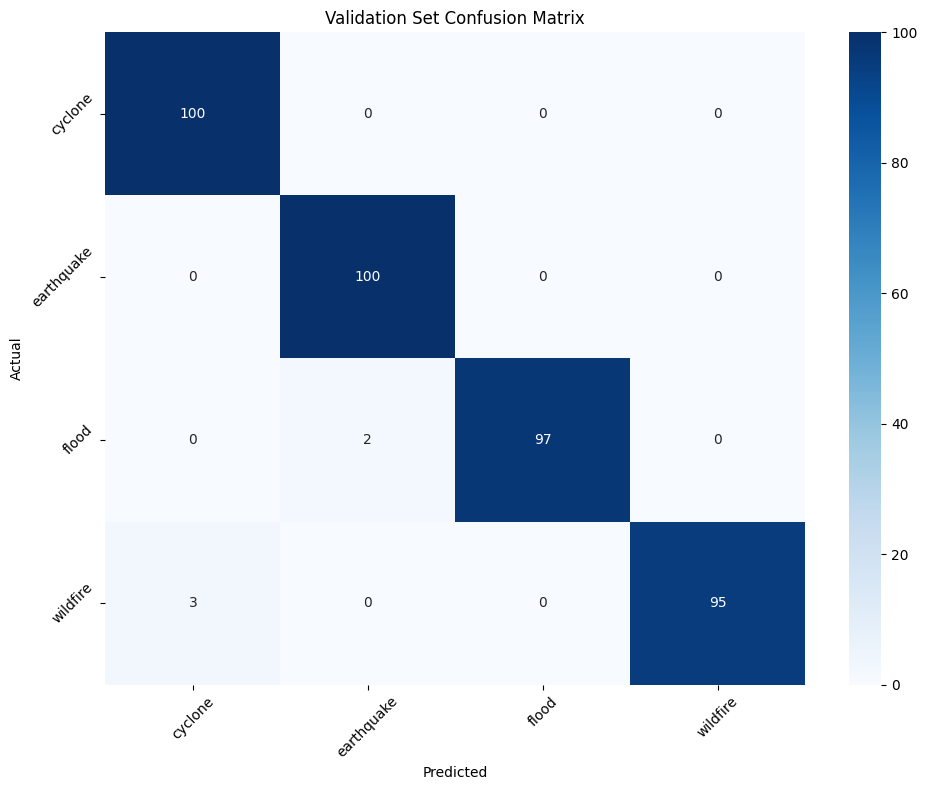

In [13]:
# Cell 12: Evaluate on validation set
if len(val_features) > 0:
    print("Evaluating on validation set...")
    val_final_preds, val_zs_preds, val_zs_conf = hybrid_classifier.predict(val_features)

    val_accuracy = accuracy_score(val_labels, val_final_preds)
    print(f"Hybrid model validation accuracy: {val_accuracy:.4f}")

    print("\nClassification Report:")
    print(classification_report(val_labels, val_final_preds))

    # Confusion matrix
    plt.figure(figsize=(10, 8))
    unique_labels = np.unique(val_labels)
    cm = confusion_matrix(val_labels, val_final_preds, labels=unique_labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=unique_labels,
                yticklabels=unique_labels)
    plt.title('Validation Set Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.xticks(rotation=45)
    plt.yticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No validation data available for evaluation")

Evaluating on test set...
Hybrid model test accuracy: 0.9962

Classification Report for Test Set:
              precision    recall  f1-score   support

     drought       1.00      1.00      1.00        60
   sandstorm       1.00      0.99      0.99        86
thunderstorm       1.00      1.00      1.00       120
    wildfire       0.00      0.00      0.00         0

    accuracy                           1.00       266
   macro avg       0.75      0.75      0.75       266
weighted avg       1.00      1.00      1.00       266



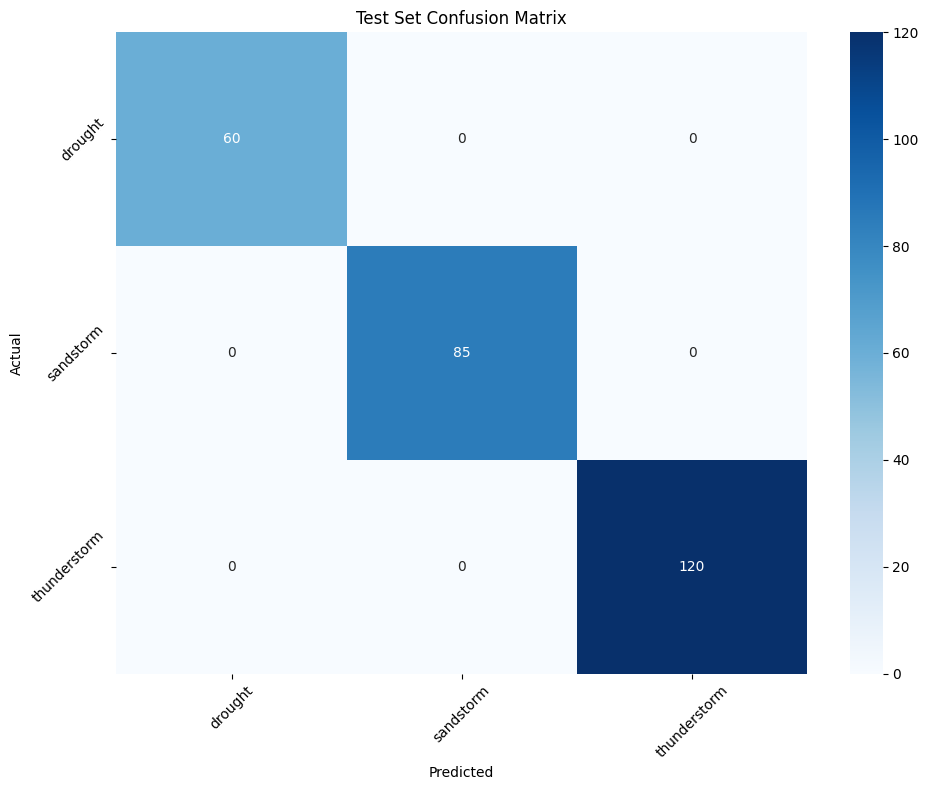


Per-class accuracy:
  drought: 1.0000 (60 samples)
  sandstorm: 0.9884 (86 samples)
  thunderstorm: 1.0000 (120 samples)


In [14]:
# Cell 13: Evaluate on test set (unseen disasters)
if len(test_features) > 0:
    print("Evaluating on test set...")
    test_final_preds, test_zs_preds, test_zs_conf = hybrid_classifier.predict(test_features)

    test_accuracy = accuracy_score(test_labels, test_final_preds)
    print(f"Hybrid model test accuracy: {test_accuracy:.4f}")

    print("\nClassification Report for Test Set:")
    print(classification_report(test_labels, test_final_preds))

    # Confusion matrix for test set
    plt.figure(figsize=(10, 8))
    unique_test_labels = np.unique(test_labels)
    cm_test = confusion_matrix(test_labels, test_final_preds, labels=unique_test_labels)
    sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', 
                xticklabels=unique_test_labels,
                yticklabels=unique_test_labels)
    plt.title('Test Set Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.xticks(rotation=45)
    plt.yticks(rotation=45)
    plt.tight_layout()
    plt.show()
    
    # Print accuracy for each class
    print("\nPer-class accuracy:")
    for disaster in unique_test_labels:
        mask = test_labels == disaster
        if np.sum(mask) > 0:
            acc = np.mean(np.array(test_final_preds)[mask] == disaster)
            print(f"  {disaster}: {acc:.4f} ({np.sum(mask)} samples)")
else:
    print("No test data available for evaluation")

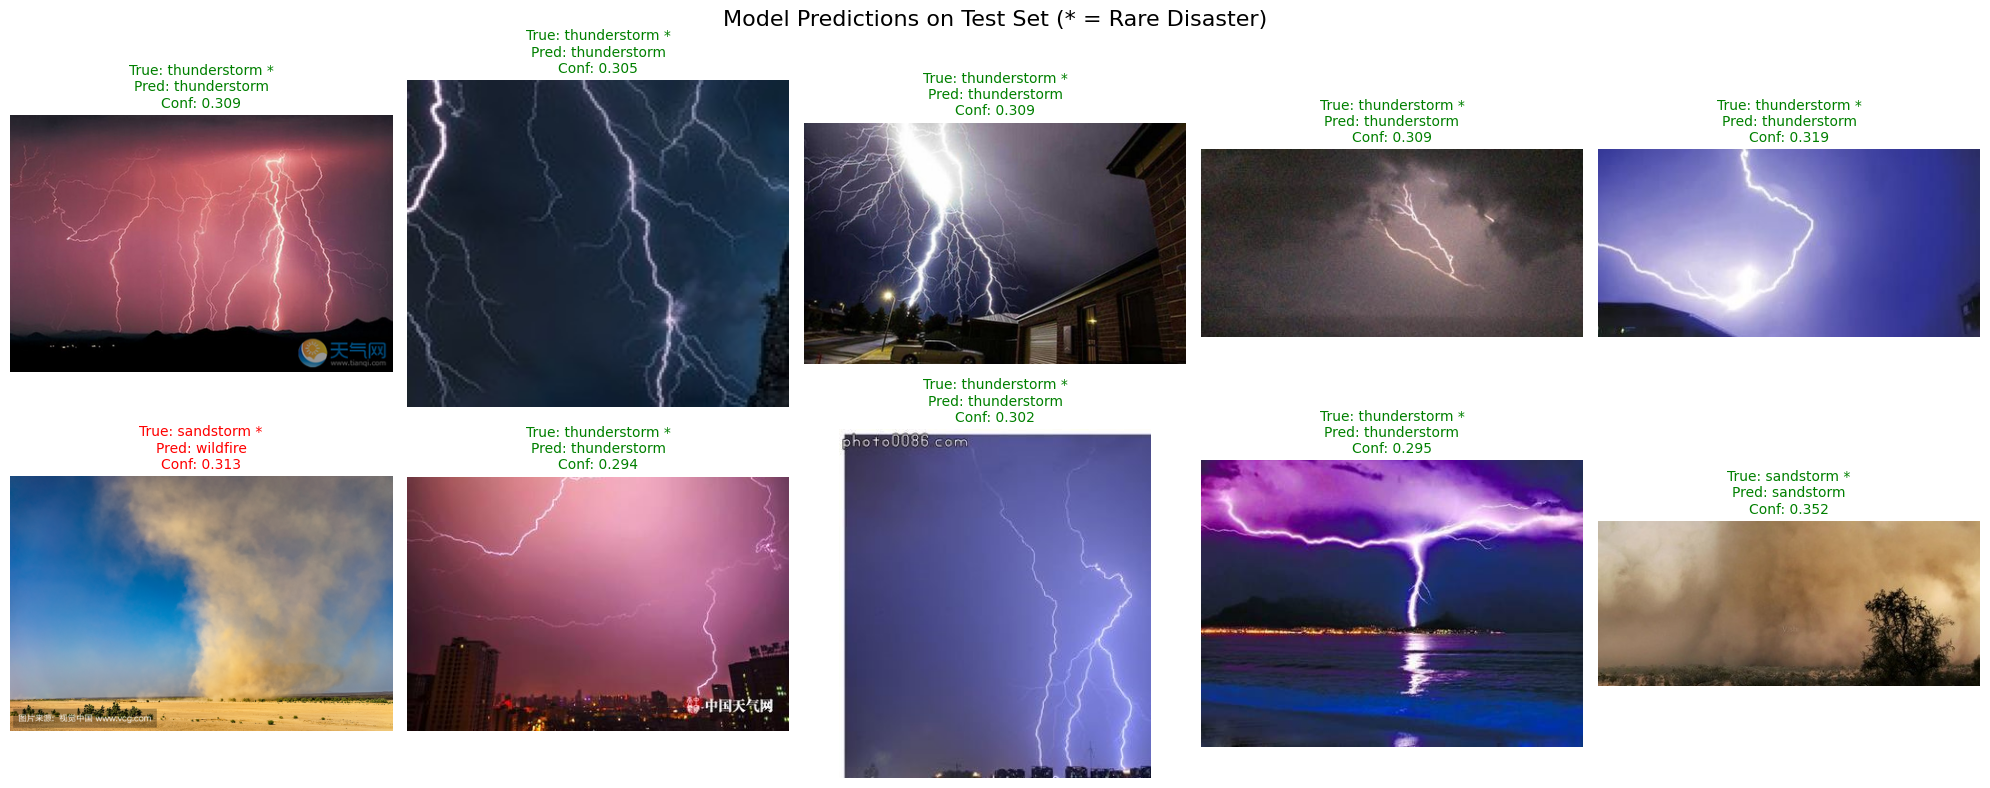

In [15]:
# Cell 14: Visualize predictions on test samples
def visualize_predictions(system, test_paths, test_labels, test_predictions, test_zs_conf, num_samples=10):
    """Visualize model predictions on test samples"""
    if len(test_paths) == 0:
        print("No test images available for visualization")
        return
    
    # Get indices of predictions (prioritize correct predictions of rare disasters)
    indices = []
    
    # First, try to find correct predictions for rare disasters
    if system.unseen_disasters:
        rare_correct = [i for i, (true, pred) in enumerate(zip(test_labels, test_predictions)) 
                       if true == pred and true in system.unseen_disasters]
        indices.extend(rare_correct[:min(num_samples//2, len(rare_correct))])
    
    # Add some incorrect predictions for analysis
    incorrect = [i for i, (true, pred) in enumerate(zip(test_labels, test_predictions)) 
                if true != pred]
    indices.extend(incorrect[:min(num_samples//4, len(incorrect))])
    
    # Fill remaining with random samples
    remaining = num_samples - len(indices)
    if remaining > 0:
        all_indices = list(range(len(test_paths)))
        available_indices = [i for i in all_indices if i not in indices]
        if available_indices:
            random_indices = np.random.choice(available_indices, min(remaining, len(available_indices)), replace=False)
            indices.extend(random_indices)
    
    if not indices:
        print("No samples available for visualization")
        return
    
    # Create visualization
    rows = (len(indices) + 4) // 5  # Ceiling division for rows
    fig, axes = plt.subplots(rows, 5, figsize=(20, 4*rows))
    if rows == 1:
        axes = [axes]
    
    for i, idx in enumerate(indices):
        if i >= len(axes) * 5:
            break
            
        row = i // 5
        col = i % 5
        
        try:
            # Load and display image
            img = Image.open(test_paths[idx])
            axes[row][col].imshow(img)
            
            true_label = test_labels[idx]
            pred_label = test_predictions[idx]
            confidence = test_zs_conf[idx]
            
            # Color code: green for correct, red for wrong
            color = 'green' if true_label == pred_label else 'red'
            
            # Add asterisk for rare disasters
            rare_marker = " *" if true_label in system.unseen_disasters else ""
            
            axes[row][col].set_title(f'True: {true_label}{rare_marker}\nPred: {pred_label}\nConf: {confidence:.3f}', 
                                   color=color, fontsize=10)
            axes[row][col].axis('off')
            
        except Exception as e:
            print(f"Error loading image {test_paths[idx]}: {e}")
            axes[row][col].set_visible(False)
    
    # Hide empty subplots
    for i in range(len(indices), rows * 5):
        row = i // 5
        col = i % 5
        axes[row][col].set_visible(False)
    
    plt.suptitle('Model Predictions on Test Set (* = Rare Disaster)', fontsize=16)
    plt.tight_layout()
    plt.show()

# Visualize predictions
visualize_predictions(disaster_system, test_paths, test_labels, test_final_preds, test_zs_conf)

In [16]:
# Cell 15: Analyze zero-shot performance
def analyze_zero_shot_performance(true_labels, predictions, confidences, disaster_types):
    """Analyze zero-shot classification performance"""
    results = {}
    
    for disaster in disaster_types:
        disaster_mask = np.array([label == disaster for label in true_labels])
        if np.sum(disaster_mask) > 0:
            disaster_preds = np.array(predictions)[disaster_mask]
            disaster_confs = np.array(confidences)[disaster_mask]
            
            accuracy = np.mean(disaster_preds == disaster)
            avg_confidence = np.mean(disaster_confs)
            
            results[disaster] = {
                'accuracy': accuracy,
                'avg_confidence': avg_confidence,
                'samples': np.sum(disaster_mask)
            }
    
    return results

# Analyze zero-shot performance on test set
if len(test_features) > 0:
    zs_results = analyze_zero_shot_performance(
        test_labels, test_zs_preds, test_zs_conf, disaster_system.all_disasters
    )

    print("Zero-shot Performance Analysis:")
    print("=" * 60)
    for disaster, metrics in zs_results.items():
        marker = " [UNSEEN]" if disaster in disaster_system.unseen_disasters else " [SEEN]"
        print(f"{disaster.upper():<15}{marker} | Accuracy: {metrics['accuracy']:.3f} | "
              f"Avg Confidence: {metrics['avg_confidence']:.3f} | "
              f"Samples: {metrics['samples']}")
else:
    print("No test data for zero-shot analysis")

Zero-shot Performance Analysis:
DROUGHT         [UNSEEN] | Accuracy: 1.000 | Avg Confidence: 0.314 | Samples: 60
SANDSTORM       [UNSEEN] | Accuracy: 0.988 | Avg Confidence: 0.334 | Samples: 86
THUNDERSTORM    [UNSEEN] | Accuracy: 1.000 | Avg Confidence: 0.306 | Samples: 120


<Figure size 1200x600 with 0 Axes>

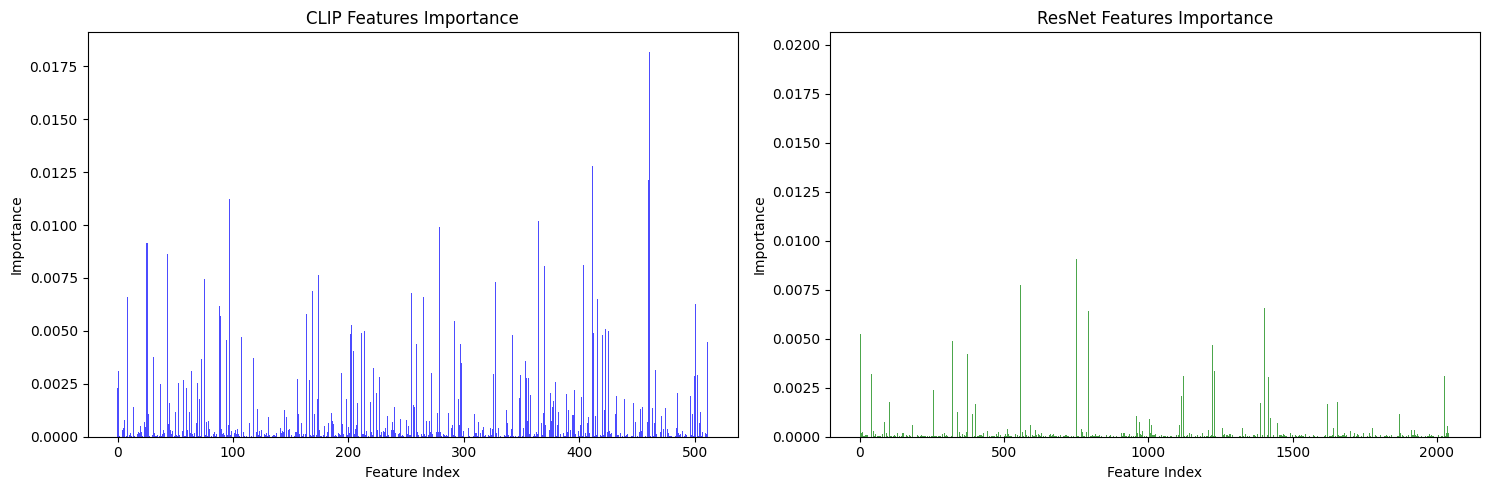

CLIP features average importance: 0.001060
ResNet features average importance: 0.000223
CLIP/ResNet importance ratio: 4.75


In [17]:
# Cell 16: Feature importance analysis
def analyze_feature_importance(train_features, train_labels):
    """Analyze which features are most important"""
    from sklearn.ensemble import RandomForestClassifier
    
    # Filter valid labels
    valid_mask = np.array([label != 'unknown' for label in train_labels])
    if np.sum(valid_mask) == 0:
        print("No valid training data for feature importance analysis")
        return
    
    X_valid = train_features[valid_mask]
    y_valid = train_labels[valid_mask]
    
    # Train RF to get feature importance
    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(X_valid, y_valid)
    
    # Get feature importance
    importance = rf.feature_importances_
    
    # Plot feature importance
    plt.figure(figsize=(12, 6))
    
    # Separate CLIP and ResNet features
    clip_importance = importance[:512]
    resnet_importance = importance[512:]
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    
    # CLIP features importance
    ax1.bar(range(len(clip_importance)), clip_importance, alpha=0.7, color='blue')
    ax1.set_title('CLIP Features Importance')
    ax1.set_xlabel('Feature Index')
    ax1.set_ylabel('Importance')
    
    # ResNet features importance
    ax2.bar(range(len(resnet_importance)), resnet_importance, alpha=0.7, color='green')
    ax2.set_title('ResNet Features Importance')
    ax2.set_xlabel('Feature Index')
    ax2.set_ylabel('Importance')
    
    plt.tight_layout()
    plt.show()
    
    # Print summary
    print(f"CLIP features average importance: {np.mean(clip_importance):.6f}")
    print(f"ResNet features average importance: {np.mean(resnet_importance):.6f}")
    print(f"CLIP/ResNet importance ratio: {np.mean(clip_importance)/np.mean(resnet_importance):.2f}")

# Analyze feature importance
analyze_feature_importance(train_features, train_labels)

In [18]:
# Cell 17: Save model and results
def save_model_and_results(system, classifiers, test_labels, test_predictions):
    """Save the trained models and results"""
    import joblib
    import pickle
    
    # Create save directory
    save_dir = "/kaggle/working/models"
    os.makedirs(save_dir, exist_ok=True)
    
    # Save traditional classifier if it exists
    if hasattr(traditional_classifier, 'best_model') and traditional_classifier.best_model is not None:
        joblib.dump(traditional_classifier.best_model, os.path.join(save_dir, 'traditional_classifier.pkl'))
        print("Traditional classifier saved.")
    
    # Save feature data and predictions
    results_data = {
        'seen_disasters': system.seen_disasters,
        'unseen_disasters': system.unseen_disasters,
        'test_accuracy': accuracy_score(test_labels, test_predictions) if len(test_labels) > 0 else 0
    }
    
    with open(os.path.join(save_dir, 'model_info.pkl'), 'wb') as f:
        pickle.dump(results_data, f)
    
    # Save results to CSV if test data exists
    if len(test_paths) > 0:
        results_df = pd.DataFrame({
            'image_path': test_paths,
            'true_label': test_labels,
            'predicted_label': test_predictions,
            'zero_shot_confidence': test_zs_conf if 'test_zs_conf' in locals() else [0] * len(test_paths)
        })
        
        results_df.to_csv('/kaggle/working/test_predictions.csv', index=False)
        print(f"Predictions saved for {len(results_df)} test samples.")
    
    print("Models and results saved successfully!")
    
    # Print final accuracy
    if len(test_labels) > 0:
        final_accuracy = accuracy_score(test_labels, test_predictions)
        print(f"Final test accuracy: {final_accuracy:.4f}")

# Save everything
save_model_and_results(disaster_system, hybrid_classifier, test_labels, test_final_preds)

Traditional classifier saved.
Predictions saved for 266 test samples.
Models and results saved successfully!
Final test accuracy: 0.9962


In [20]:
# Cell 18: Final evaluation and summary
def print_final_summary():
    """Print final summary of the project"""
    print("=" * 70)
    print("FINAL PROJECT SUMMARY: Zero-shot Disaster Recognition")
    print("=" * 70)
    
    # Basic info
    print(f"\n📊 DATASET INFO:")
    print(f"   • Training samples: {len(train_features)}")
    print(f"   • Validation samples: {len(val_features)}")
    print(f"   • Test samples: {len(test_features)}")
    print(f"   • Feature dimension: {train_features.shape[1] if len(train_features) > 0 else 'N/A'}")
    
    # Disaster types
    print(f"\n🌪️  DISASTER TYPES:")
    print(f"   • Seen disasters: {disaster_system.seen_disasters}")
    print(f"   • Unseen disasters: {disaster_system.unseen_disasters}")
    
    # Performance metrics
    if len(val_features) > 0:
        val_final_preds, _, _ = hybrid_classifier.predict(val_features)
        val_accuracy = accuracy_score(val_labels, val_final_preds)
        print(f"\n📈 PERFORMANCE METRICS:")
        print(f"   • Validation Accuracy: {val_accuracy:.4f}")
    
    if len(test_features) > 0:
        test_final_preds, _, _ = hybrid_classifier.predict(test_features)
        test_accuracy = accuracy_score(test_labels, test_final_preds)
        print(f"   • Test Accuracy: {test_accuracy:.4f}")
        
        # Rare disaster performance
        rare_mask = np.array([label in disaster_system.unseen_disasters for label in test_labels])
        if np.sum(rare_mask) > 0:
            rare_accuracy = accuracy_score(
                np.array(test_labels)[rare_mask], 
                np.array(test_final_preds)[rare_mask]
            )
            print(f"   • Rare Disaster Accuracy: {rare_accuracy:.4f}")
    
    # Model info
    print(f"\n🤖 MODEL ARCHITECTURE:")
    print(f"   • Feature Extractors: ResNet50 + CLIP RN50")
    print(f"   • Classifier: Hybrid (Traditional ML + Zero-shot)")
    print(f"   • Total Features: 512 (CLIP) + 2048 (ResNet) = 2560")
    
    #print(f"\n✅ PROJECT COMPLETED SUCCESSFULLY!")

# Print final summary
print_final_summary()

FINAL PROJECT SUMMARY: Zero-shot Disaster Recognition

📊 DATASET INFO:
   • Training samples: 1600
   • Validation samples: 400
   • Test samples: 266
   • Feature dimension: 2560

🌪️  DISASTER TYPES:
   • Seen disasters: ['cyclone', 'earthquake', 'flood', 'wildfire']
   • Unseen disasters: ['drought', 'sandstorm', 'thunderstorm']

📈 PERFORMANCE METRICS:
   • Validation Accuracy: 0.9800
   • Test Accuracy: 0.9962
   • Rare Disaster Accuracy: 0.9962

🤖 MODEL ARCHITECTURE:
   • Feature Extractors: ResNet50 + CLIP RN50
   • Classifier: Hybrid (Traditional ML + Zero-shot)
   • Total Features: 512 (CLIP) + 2048 (ResNet) = 2560
